# Day 7: Task 2 and Task 3
System 7 Internship | Week 2 | Aayla Zahid Butt

- **Task 2:** House-price predictor (multiple linear regression)
- **Task 3:** Basic classification model with feature importance

## Task 2: House-price predictor

In [1]:
import numpy as np
import pandas as pd

# create the house-price dataset (500 houses)
rng = np.random.default_rng(42)
n = 500
area = rng.normal(1800, 500, n).clip(500, 4000).round(0)
bedrooms = np.clip((area / 700 + rng.normal(0, 0.7, n)).round(), 1, 6).astype(int)
bathrooms = np.clip((bedrooms * 0.7 + rng.normal(0, 0.6, n)).round(), 1, 5).astype(int)
age = rng.integers(0, 50, n)
dist = rng.uniform(1, 25, n).round(1)
price = (35000 + 120 * area + 8000 * bedrooms + 12000 * bathrooms
         - 900 * age - 2500 * dist + rng.normal(0, 25000, n)).round(0)

df = pd.DataFrame(dict(area_sqft=area, bedrooms=bedrooms, bathrooms=bathrooms,
                       house_age=age, dist_city_km=dist, price=price))

# make a few values missing on purpose to practise cleaning
df.loc[rng.choice(n, 12, replace=False), 'house_age'] = np.nan
df.loc[rng.choice(n, 8, replace=False), 'dist_city_km'] = np.nan
df.to_csv('house_prices.csv', index=False)

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('house_prices.csv')

# fill missing values with the median
df['house_age'] = df['house_age'].fillna(df['house_age'].median())
df['dist_city_km'] = df['dist_city_km'].fillna(df['dist_city_km'].median())

X = df.drop(columns='price')
y = df['price']

# 70% train, 15% validation, 15% test
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42)
print(len(X_tr), len(X_val), len(X_te))

350 75 75


In [4]:
multi = LinearRegression().fit(X_tr, y_tr)

print('Coefficients:')
for name, coef in zip(X.columns, multi.coef_):
    print(f'  {name:14s} {coef:10.2f}')
print('  intercept     ', round(multi.intercept_, 2))

Coefficients:
  area_sqft          123.54
  bedrooms          5137.87
  bathrooms        12551.71
  house_age         -905.41
  dist_city_km     -2932.39
  intercept      40031.56


The signs make sense: bigger houses cost more, and older or farther houses cost less.

In [5]:
for label, Xs, ys in [('Validation', X_val, y_val), ('Test', X_te, y_te)]:
    pred = multi.predict(Xs)
    print(label, 'MAE :', round(mean_absolute_error(ys, pred)))
    print(label, 'RMSE:', round(np.sqrt(mean_squared_error(ys, pred))))
    print(label, 'R2  :', round(r2_score(ys, pred), 3))
    print()

Validation MAE : 20915
Validation RMSE: 25545
Validation R2  : 0.914

Test MAE : 20870
Test RMSE: 26345
Test R2  : 0.84



On the test set the model explains about 84% of the variation in price. The test R2 is lower than the validation R2 because each set has only 75 rows, so the score changes from one split to another.

In [6]:
new = pd.DataFrame([dict(area_sqft=2200, bedrooms=4, bathrooms=3,
                         house_age=10, dist_city_km=8)])
print('Predicted price for the new house:', round(multi.predict(new)[0]))

Predicted price for the new house: 337522


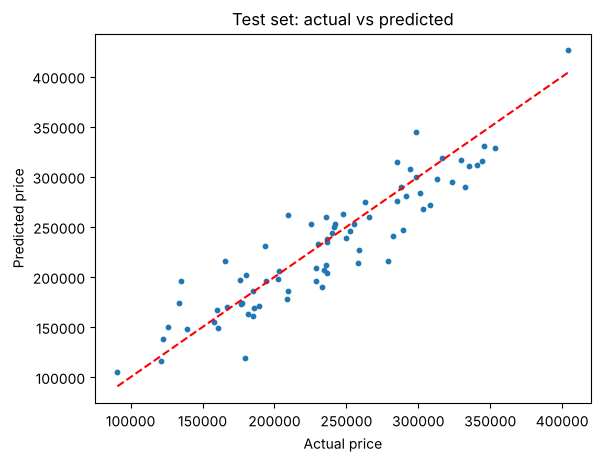

In [7]:
pred = multi.predict(X_te)
plt.scatter(y_te, pred, s=10)
plt.plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], 'r--')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Test set: actual vs predicted')
plt.show()

## Task 3: Classification model
The Breast Cancer dataset is used, with four models: logistic regression, KNN, decision tree and random forest.

In [8]:
bc = load_breast_cancer(as_frame=True)
Xc, yc = bc.data, bc.target
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc)

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
models = {'Logistic Regression': lr, 'KNN (k=5)': knn,
          'Decision Tree (depth 4)': dt, 'Random Forest (200 trees)': rf}

for name, m in models.items():
    m.fit(Xc_tr, yc_tr)
    pred = m.predict(Xc_te)
    print(name, 'accuracy:', round(m.score(Xc_te, yc_te), 3))
    print(confusion_matrix(yc_te, pred))
    print()

Logistic Regression accuracy: 0.982


[[41  1]
 [ 1 71]]

KNN (k=5) accuracy: 0.956
[[39  3]
 [ 2 70]]

Decision Tree (depth 4) accuracy: 0.939
[[39  3]
 [ 4 68]]



Random Forest (200 trees) accuracy: 0.956
[[39  3]
 [ 2 70]]



Logistic regression was the best with 98.2% (2 wrong out of 114). KNN and random forest got 95.6% and the decision tree got 93.9%. The test set is small, so one extra mistake changes accuracy by about 0.9%. The difference between the top models is therefore small.

In [9]:
print(classification_report(yc_te, rf.predict(Xc_te), target_names=bc.target_names))

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## Feature importance

Random forest top 5 features:
worst perimeter         0.133
worst area              0.128
worst concave points    0.108
mean concave points     0.094
worst radius            0.091
dtype: float64


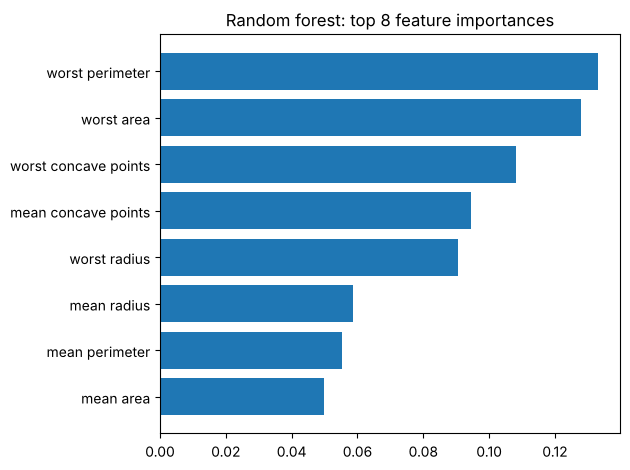

In [10]:
imp = pd.Series(rf.feature_importances_, index=Xc.columns)
imp = imp.sort_values(ascending=False)
print('Random forest top 5 features:')
print(imp.head(5).round(3))

top = imp.head(8)[::-1]
plt.barh(top.index, top.values)
plt.title('Random forest: top 8 feature importances')
plt.tight_layout()
plt.show()

The random forest mainly uses the size of the cell nucleus (perimeter, area, radius) and concave points. High importance means the feature helps the prediction, it does not prove it is the cause.

In [11]:
coef = pd.Series(lr.named_steps['logisticregression'].coef_[0], index=Xc.columns)
print('Logistic regression, 5 largest coefficients (features are standardised):')
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(5).round(3))

dimp = pd.Series(dt.feature_importances_, index=Xc.columns)
print()
print('Decision tree top 3 features:')
print(dimp.sort_values(ascending=False).head(3).round(3))

Logistic regression, 5 largest coefficients (features are standardised):
worst texture          -1.255
radius error           -1.083
worst concave points   -0.954
worst area             -0.948
worst radius           -0.948
dtype: float64

Decision tree top 3 features:
worst radius            0.734
worst concave points    0.122
texture error           0.046
dtype: float64


In this dataset label 1 means benign, so a negative coefficient pushes the prediction towards malignant. The single tree puts about 73% of its importance on worst radius, while the forest spreads it over several related features, so it is more stable.